


# Vamos encher o carrinho!

# Introdução

O Instacart é uma plataforma de entrega de supermercado onde os clientes podem fazer um pedido no supermercado e depois receber sua compra, semelhante ao funcionamento do Uber Eats e do iFood. O conjunto de dados que fornecemos foi modificado a partir do original. Reduzimos o tamanho dele para que seus cálculos sejam executados mais rapidamente e incluímos valores ausentes e duplicados. Também tivemos o cuidado de preservar as distribuições dos dados originais quando fizemos as alterações.

Você precisa completar três etapas. Para cada uma delas, escreva uma breve introdução descrevendo como você pretende concluir a etapa e justifique suas decisões em parágrafos explicativos a medida que você avança na solução. Escreva também uma conclusão para resumir suas conclusões e escolhas.



## Dicionário de dados

Há cinco tabelas no conjunto de dados, e você vai precisar usar todas elas para pré-processar seus dados e fazer AED. Abaixo está um dicionário que lista as colunas de cada tabela e descreve os dados contidos nelas.

- `instacart_orders.csv`: cada linha corresponde a um pedido no aplicativo da Instacart
    - `'order_id'`: é o número que identifica cada pedido de forma exclusiva
    - `'user_id'`: é o número de identificação exclusivo da conta de cada cliente
    - `'order_number'`: é o número de vezes que o cliente fez um pedido
    - `'order_dow'`: é o dia da semana em que o pedido foi feito (0 é domingo)
    - `'order_hour_of_day'`: é a hora do dia em que o pedido foi feito
    - `'days_since_prior_order'`: é o número de dias desde que o cliente fez seu pedido anterior




- `products.csv`: cada linha corresponde a um produto exclusivo que os clientes podem comprar
    - `'product_id'`: é o número de identificação unívoco de cada produto
    - `'product_name'`: é o nome do produto
    - `'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    - `'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado




-	`order_products.csv`: cada linha corresponde a um item incluído em um pedido
    -	`'order_id'`: é o número que identifica cada pedido de forma exclusiva
    -	`'product_id'`: é o número de identificação exclusivo de cada produto
    -	`'add_to_cart_order'`: é a ordem sequencial em que cada item foi colocado no carrinho
    -	`'reordered'`: 0 se o cliente nunca comprou o produto antes, 1 se já o comprou




-	`aisles.csv`
    -	`'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    -	`'aisle'`: é o nome do corredor



-	`departments.csv`
    -	`'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado
    -	`'department'`: é o nome do departamento


# Etapa 1. Visão geral dos dados

Leia os arquivos de dados (/datasets/instacart_orders.csv, /datasets/products.csv, /datasets/aisles.csv, /datasets/departments.csv e /datasets/order_products.csv) com `pd.read_csv()` usando os parâmetros apropriados para fazer isso corretamente. Verifique as informações para cada DataFrame criado.


## Plano de solução

Escreva aqui seu plano para a Etapa 2. Visão geral dos dados

Para a etapa 2 o plano é verificar se existem valores duplicados ou ausentes, verificar se é necessário colocar os nomes em letras minusculas e remover os valores duplicados .

In [4]:
import pandas as pd 

In [65]:
# leia os conjuntos de dados em DataFrames
df_instacart_orders = pd.read_csv('/datasets/instacart_orders.csv', sep=';') # lendo o arquivo csv dos dados de instacart_orders.csv e redefinindo o sepador ';' para melhor leitura dos dados em Pandas
df_products = pd.read_csv('/datasets/products.csv', sep=';') # lendo o arquivo csv dos dados de products.csv com separador redefinido
df_aisles = pd.read_csv('/datasets/aisles.csv', sep=';') # lendo o arquivo csv dos dados de aisles.csv com separador redefinido
df_departments = pd.read_csv('/datasets/departments.csv', sep=';') # lendo o arquivo csv dos dados de departments.csv com separador redefinido 
df_order_products = pd.read_csv('/datasets/order_products.csv', sep=';') # lendo o arquivo csv dos dados de order_products.csv com separador redefinido

In [3]:
# imprima as informações sobre o DataFrame
print(df_instacart_orders.head()) # imprimindo as  primeiras 5 linhas do DataFrame
print() # dando espaço para melhor visualização das informações contidas nos dados
df_instacart_orders.info() # imprimindo as informações do DataFrame

   order_id  user_id  order_number  order_dow  order_hour_of_day  \
0   1515936   183418            11          6                 13   
1   1690866   163593             5          5                 12   
2   1454967    39980             4          5                 19   
3   1768857    82516            56          0                 20   
4   3007858   196724             2          4                 12   

   days_since_prior_order  
0                    30.0  
1                     9.0  
2                     2.0  
3                    10.0  
4                    17.0  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-nu

In [4]:
# imprima as informações sobre o DataFrame
print(df_products.head()) # imprimindo as  primeiras 5 linhas do DataFrame
print()  # dando espaço para melhor visualização das informações contidas nos dados
df_products.info() # imprimindo as informações do DataFrame

   product_id                                       product_name  aisle_id  \
0           1                         Chocolate Sandwich Cookies        61   
1           2                                   All-Seasons Salt       104   
2           3               Robust Golden Unsweetened Oolong Tea        94   
3           4  Smart Ones Classic Favorites Mini Rigatoni Wit...        38   
4           5                          Green Chile Anytime Sauce         5   

   department_id  
0             19  
1             13  
2              7  
3              1  
4             13  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [5]:
# imprima as informações sobre o DataFrame
print(df_aisles.head()) # imprimindo as  primeiras 5 linhas do DataFrame
print()  # dando espaço para melhor visualização das informações contidas nos dados
df_aisles.info() # imprimindo as informações do DataFrame

   aisle_id                       aisle
0         1       prepared soups salads
1         2           specialty cheeses
2         3         energy granola bars
3         4               instant foods
4         5  marinades meat preparation

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [6]:
# imprima as informações sobre o DataFrame
print(df_departments.head()) # imprimindo as  primeiras 5 linhas do DataFrame
print()  # dando espaço para melhor visualização das informações contidas nos dados
df_departments.info() # imprimindo as informações do DataFrame

   department_id department
0              1     frozen
1              2      other
2              3     bakery
3              4    produce
4              5    alcohol

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes


In [51]:
# imprima as informações sobre o DataFrame
print(df_order_products.head()) # imprimindo as  primeiras 5 linhas do DataFrame
print()  # dando espaço para melhor visualização das informações contidas nos dados
df_order_products.info(show_counts=True) # imprimindo as informações do DataFrame incluindo o parâmetro show_counts=True para mostrar explicitamente a quantidade de valores não nulos em cada coluna.

   order_id  product_id  add_to_cart_order  reordered
0   2141543       11440                 17          0
1    567889        1560                  1          1
2   2261212       26683                  1          1
3    491251        8670                 35          1
4   2571142        1940                  5          1

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   order_id           4545007 non-null  int64
 1   product_id         4545007 non-null  int64
 2   add_to_cart_order  4545007 non-null  int64
 3   reordered          4545007 non-null  int64
dtypes: int64(4)
memory usage: 138.7 MB


## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 1. Visão geral dos dados

Os dados dos DataFrames estavam com os sepadores definidos como ponto e virgula(;) e o read_csv() por padrão espera vírgula (,). Então, o Pandas leu tudo como uma única coluna, tornando a leitura dos dados dificil de compreender sem a chamada de sep='' para orgazinar as colunas. 
Também é possivel encontrar valores não nulos  nos DataFrames df_instacart_orders na coluna 6 'days_since_prior_order' , em df_products na coluna 2 'product_name' e df_order_products na coluna 3 'add_to_cart_order' .

# Etapa 2. Preparação de dados

Faça o pré-processamento dos dados da seguinte maneira:

-	Verifique e corrija os tipos de dados (por exemplo, certifique-se de que as colunas de ID sejam números inteiros)
-	Identifique e preencha valores ausentes
-	Identifique e remova valores duplicados

Certifique-se de explicar que tipos de valores ausentes e duplicados você encontrou, como você os preencheu ou removeu, por que escolheu esses métodos e por que você acha que esses valores ausentes e duplicados estavam presentes no conjunto de dados.

## Plano de solução

Escreva aqui seu plano para a Etapa 2. Preparação de dados

## Encontre e remova valores duplicados (e descreva por que você está fazendo suas escolhas)

### DataFrame `instacart_orders`

In [8]:
# Verificar se há pedidos duplicados
instacart_duplicated = df_instacart_orders.duplicated()
print(df_instacart_orders[df_instacart_orders.duplicated()])
print('existem:', instacart_duplicated.sum(), 'valores duplicados')

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
145574    794638    50898            24          3                  2   
223105   2160484   107525            16          3                  2   
230807   1918001   188546            14          3                  2   
266232   1782114   106752             1          3                  2   
273805   1112182   202304            84          3                  2   
284038   2845099    31189            11          3                  2   
311713   1021560    53767             3          3                  2   
321100    408114    68324             4          3                  2   
323900   1919531   191501            32          3                  2   
345917   2232988    82565             1          3                  2   
371905    391768    57671            19          3                  2   
394347    467134    63189            21          3                  2   
411408   1286742   183220            48          3 

Há linhas duplicadas? Se sim, o que elas têm em comum

Foram identificadas 15 observações duplicadas no conjunto de dados. Após inspeção, verificou-se que se tratavam de registros completamente idênticos exceto na coluna 'days_since_prior_order' que contém 2 valores ausentes. 
- Todos feitos na quarta-feira (order_dow = 3)
- Todos feitos às 2h da manhã (order_hour_of_day = 2)
- Diferem apenas em 'days_since_prior_order'

In [9]:
# Com base nas suas conclusões,

# verifique todos os pedidos feitos às 2h da manhã nas quartas-feiras
instacart_orders_wed_2AM = df_instacart_orders[(df_instacart_orders['order_hour_of_day'] == 2) & (df_instacart_orders['order_dow'] == 3)]
print(instacart_orders_wed_2AM)
print('quantidade de pedidos:', instacart_orders_wed_2AM.shape[0])


        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

O que esse resultado quer dizer?
Foram encontrados 121 pedidos feitos na quarta-feira ás 2 da manhã, sendo 15 deles duplicados e 106 pedidos únicos e válidos.

In [10]:

# Remova pedidos duplicados
instacart_drop = df_instacart_orders.drop_duplicates()
instacart_drop = instacart_drop.reset_index(drop=True)
print(instacart_drop)
print("Duplicados restantes:", instacart_drop.duplicated().sum())
print("Antes:", df_instacart_orders.shape[0])
print("Depois:", instacart_drop.shape[0])
print("Removidos:", df_instacart_orders.shape[0] - instacart_drop.shape[0])


        order_id  user_id  order_number  order_dow  order_hour_of_day  \
0        1515936   183418            11          6                 13   
1        1690866   163593             5          5                 12   
2        1454967    39980             4          5                 19   
3        1768857    82516            56          0                 20   
4        3007858   196724             2          4                 12   
...          ...      ...           ...        ...                ...   
478947   3210681     5617             5          1                 14   
478948   3270802   112087             2          3                 13   
478949    885349    82944            16          2                 11   
478950    216274     4391             3          3                  8   
478951   2071924     1730            18          1                 14   

        days_since_prior_order  
0                         30.0  
1                          9.0  
2                       

In [11]:

# Verifique as linhas duplicadas mais uma vez
instacart_duplicated = instacart_drop.duplicated(keep=False)
print(instacart_duplicated)
print("Duplicados restantes:", instacart_duplicated.sum())
print('Linhas originais:', df_instacart_orders.shape[0])
print('Linhas após a limpeza:', instacart_drop.shape[0])
print('Linhas removidas:', df_instacart_orders.shape[0] - instacart_drop.shape[0])

0         False
1         False
2         False
3         False
4         False
          ...  
478947    False
478948    False
478949    False
478950    False
478951    False
Length: 478952, dtype: bool
Duplicados restantes: 0
Linhas originais: 478967
Linhas após a limpeza: 478952
Linhas removidas: 15


In [12]:
# Verifique novamente apenas os IDs de pedidos duplicados
duplicated_ids = df_instacart_orders[
    df_instacart_orders['order_id'].duplicated(keep=False)
    ]
print(duplicated_ids.sort_values('order_id'))
print()
print(df_instacart_orders['order_id'].duplicated().sum())


        order_id  user_id  order_number  order_dow  order_hour_of_day  \
354993    391768    57671            19          3                  2   
371905    391768    57671            19          3                  2   
119251    408114    68324             4          3                  2   
321100    408114    68324             4          3                  2   
394347    467134    63189            21          3                  2   
250626    467134    63189            21          3                  2   
99462     794638    50898            24          3                  2   
145574    794638    50898            24          3                  2   
311713   1021560    53767             3          3                  2   
242618   1021560    53767             3          3                  2   
164581   1112182   202304            84          3                  2   
273805   1112182   202304            84          3                  2   
314427   1286742   183220            48          3 



Descreva brevemente suas conclusões e o que você fez com elas.

Durante a etapa de verificação da qualidade dos dados, foi realizada uma análise para identificar possíveis registros duplicados no conjunto de dados 'df_instacart_orders'.

Utilizando o método duplicated(), foram identificadas 15 observações duplicadas no DataFrame original.

Após inspeção, verificou-se que essas linhas eram completamente idênticas em todas as colunas, indicando duplicação integral de registros.

Para garantir a integridade dos dados e evitar distorções em análises subsequentes, as duplicatas foram removidas utilizando:

instacart_drop = df_instacart_orders.drop_duplicates()

instacart_drop = instacart_drop.reset_index(drop=True)

Após a remoção, uma nova verificação confirmou que não restaram registros duplicados.

Resultado da limpeza:

- Total de registros antes: 478.967

- Total após remoção: 478.952

- Registros removidos: 15

- Duplicatas remanescentes: 0

Essa etapa assegura maior confiabilidade estatística e consistência nas análises posteriores confirmando que os dados estão prontos para análise
e elimina dúvidas sobre a qualidade dos dados.

### DataFrame `products`

In [13]:

# Verifique se há linhas completamente 
df_products_duplicated = df_products.duplicated(keep=False).sum()
print(df_products_duplicated)


0


In [14]:


# Verifique apenas IDs dos produtos duplicados
df_id_duplicated = df_products['product_id'].duplicated(keep=False).sum()
print(df_id_duplicated)



0


In [15]:


# Verifique apenas nomes de produtos duplicados (converta os nomes para minúsculas para uma comparação melhor)

names_lower = df_products['product_name'].str.lower()

df_name_duplicated = names_lower.duplicated().sum()

duplicated = df_products[names_lower.duplicated(keep=False)]

print(duplicated.sort_values('product_name'))
print('existem:', df_name_duplicated, 'valores duplicados')




       product_id                               product_name  aisle_id  \
31844       31845  18-In-1 Hemp Peppermint Pure-Castile Soap        25   
23339       23340  18-in-1 Hemp Peppermint Pure-Castile Soap        25   
19941       19942            Aged Balsamic Vinegar Of Modena        19   
13152       13153            Aged Balsamic Vinegar of Modena        19   
22582       22583         Albacore Solid White Tuna In Water        95   
...           ...                                        ...       ...   
49552       49553                                        NaN       100   
49574       49575                                        NaN       100   
49640       49641                                        NaN       100   
49663       49664                                        NaN       100   
49668       49669                                        NaN       100   

       department_id  
31844             11  
23339             11  
19941             13  
13152             1

In [16]:


# Verifique os nomes de produtos duplicados que não estão faltando
duplicates = df_products[
    df_products['product_name'].notna() &
    df_products['product_name'].str.strip().str.lower().duplicated(keep=False)
]

print(duplicates)



       product_id                                     product_name  aisle_id  \
41             42                                  Biotin 1000 mcg        47   
185           186       Fresh Scent Dishwasher Detergent with Dawn        74   
515           516                           American Cheese Slices        21   
1538         1539                                 Cauliflower head        83   
1783         1784              NUTrition Protein Mix Blueberry Nut       117   
...           ...                                              ...       ...   
49689       49690                    HIGH PERFORMANCE ENERGY DRINK        64   
49690       49691                    ORIGINAL PANCAKE & WAFFLE MIX       130   
49691       49692  ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR       130   
49692       49693                           SPRING WATER BODY WASH       127   
49693       49694                          BURRITO- STEAK & CHEESE        38   

       department_id  
41              

Descreva brevemente suas conclusões e o que você fez com elas.

Foi realizada uma análise para identificar nomes de produtos duplicados no conjunto df_products, verificou-se que não existem linhas completamente duplicadas nas colunas e não há id de produtos duplicados em 'product_id', porém foram identificados registros com 1361 nomes de produtos idênticos na coluna 'product_name' após a padronização textual. 
Para garantir uma comparação adequada, foi realizado o seguinte pré-processamento:

- Exclusão de valores nulos;

- Remoção de espaços em branco no início e no fim dos nomes;

- Conversão de todos os caracteres para minúsculas.

- Após a padronização, utilizou-se o método duplicated(keep=False) para identificar todas as ocorrências de nomes repetidos.

### DataFrame `departments`

In [17]:

# Verifique se há linhas completamente duplicadas

df_departments_duplicated = df_departments.duplicated(keep=False).sum()
print(df_departments_duplicated)




0


In [18]:


# Verifique apenas IDs duplicados de departamentos
df_ids_duplicated = df_departments['department_id'].duplicated().sum()
print(df_ids_duplicated)



0


Descreva brevemente suas conclusões e o que você fez com elas.

Foi aplicada a função duplicated() especificamente no DataFrame e na coluna 'department_id', contabilizando-se as ocorrências repetidas por meio do método .sum().

Zero duplicados indica que:

- Não há valores duplicados no DataFrame
- Cada departamento tem um ID único e exclusivo
- A integridade dos dados está preservada
- Não há conflitos de identificação entre departamentos
- Os dados estão bem estruturados para análises futuras
- duplicated(keep=False) marca todas as ocorrências de IDs repetidos (inclusive a primeira). 

### DataFrame `aisles`

In [19]:


# Verifique se há linhas completamente duplicadas

df_aisles_duplicated = df_aisles.duplicated(keep=False).sum()
print(df_aisles_duplicated)



0


In [20]:


# Verifique apenas IDs duplicados de corredores
df_aislesid_duplicated = df_aisles['aisle_id'].duplicated(keep=False).sum()
print(df_aislesid_duplicated)



0


Descreva brevemente suas conclusões e o que você fez com elas.

Foi aplicada a função duplicated(keep=False) especificamente no DataFrame e na coluna 'aisle_id', contabilizando-se as ocorrências repetidas por meio do método .sum().

Zero duplicados indica que:

- Não há valores duplicados no DataFrame
- Cada departamento tem um ID único e exclusivo
- A integridade dos dados está preservada
- Não há conflitos de identificação entre departamentos
- Os dados estão bem estruturados para análises futuras
- duplicated(keep=False) marca todas as ocorrências de IDs repetidos (inclusive a primeira). 



### DataFrame `order_products`

In [21]:

# Verifique se há linhas completamente duplicadas
df_order_products_duplicated = df_order_products.duplicated().sum()
print(df_order_products_duplicated)


0


In [22]:
# Verifique mais uma vez se há outros casos complicados de duplicados
df_order_products.duplicated(
    subset=['order_id', 'product_id'],
    keep=False
).sum()

0

Descreva brevemente suas conclusões e o que você fez com elas

Não há valores duplicados

## Encontre e remova valores ausentes


Ao processarmos valores duplicados, observamos que também temos valores ausentes que precisamos investigar nas seguintes colunas:

*	A coluna `'product_name'` da tabela products.
*	A coluna `'days_since_prior_order'` da tabela orders.
*	A coluna `'add_to_cart_order'` da tabela order_products.


### DataFrame `products`

In [23]:
# Encontre valores ausentes na coluna 'product_name'
df_products.info()
print(df_products['product_name'].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
NaN                                                          1258
HE Liquid Laundry Detergent with Downy- April Fresh scent       1
Pomegranate Dried Cranberries                                   1
Special K Red Berries Cereal Bars                               1
Pro Health Toothbrush- Soft                                     1
                                                             ... 
Onion Soup Mix                                                  1
CopperTop AAA Alkaline                                          1
Chilled Coconut Water                                   

Descreva brevemente suas conclusões.

Com base no resultado apresentado, é possível concluir que:

- Existem 1.258 valores ausentes (NaN) na coluna product_name.

- Os demais produtos aparecem, em sua maioria, com frequência igual a 1, indicando que não há repetição significativa de nomes (ao menos na forma original).

- O total de valores distintos (incluindo NaN) é 48.437, o que demonstra alta variedade de produtos cadastrados.

In [24]:
# Todos os nomes de produtos ausentes estão associados com o corredor de ID 100
df_products[df_products['product_name'].isna()]['aisle_id'].value_counts()
print(df_aisles[df_aisles['aisle_id'] == 100])
df_products[df_products['aisle_id'] == 100]['department_id'].value_counts()

    aisle_id    aisle
99       100  missing


21    1258
Name: department_id, dtype: int64

Descreva brevemente suas conclusões.

A verificação confirmou que todos os registros com product_name ausente estão associados ao aisle_id = 100. Além disso, a consulta na tabela df_aisles permitiu identificar a descrição correspondente a esse corredor.

Esse resultado demonstra que os valores ausentes não estão distribuídos aleatoriamente, mas concentrados em um único corredor específico. Isso sugere uma possível categoria técnica, genérica ou incompleta no cadastro dos produtos vinculados ao corredor 100.
Todos os 1.258 produtos sem nome estão:

- Corredor ID 100: "missing"
- Departamento ID 21:

In [25]:

# Todos os nomes de produtos ausentes estão associados com o departamento de ID 21?
print(df_departments[df_departments['department_id'] == 21])

    department_id department
20             21    missing


Descreva brevemente suas conclusões.

Além disso, ao verificar os department_id associados ao aisle_id = 100, observou-se que esses produtos pertencem a um único departamento, reforçando que a inconsistência está estruturalmente concentrada.
Portanto, os valores ausentes não são aleatórios, mas relacionados a uma categoria específica da base de dados. Isso sugere um problema localizado de cadastro ou uma categoria técnica/placeholder, facilitando um tratamento direcionado (como preenchimento padronizado ou revisão específica desses registros).

In [26]:
# Use as tabelas department e aisle para verificar os dados do corredor com ID 100 e do departamento com ID 21.
print('Informações do corredor ID 110:')
print(df_aisles[df_aisles['aisle_id'] == 100 ])
print('Informações do departamento ID 21:')
print(df_departments[df_departments['department_id'] == 21])

Informações do corredor ID 110:
    aisle_id    aisle
99       100  missing
Informações do departamento ID 21:
    department_id department
20             21    missing


Descreva brevemente suas conclusões.

A verificação das tabelas auxiliares mostrou as informações associadas ao aisle_id = 100 e ao department_id = 21. Isso permite contextualizar os registros que apresentavam product_name ausente.

Como todos os valores ausentes estavam vinculados a esse corredor e a esse departamento, conclui-se que a inconsistência está concentrada em uma categoria específica da base. Isso sugere:

- Possível categoria técnica ou placeholder;

- Falha localizada no cadastro dos produtos;

- Problema específico na importação desses registros.

Por estar restrito a uma única combinação de corredor e departamento, o tratamento pode ser realizado de forma direcionada, sem comprometer o restante da base de dados.

In [27]:

# Preencha nomes de produtos ausentes com 'Unknown'
df_products['product_name'] = df_products['product_name'].fillna('Unknown')
print(df_products['product_name'].head(20))
print(f"Valores ausentes após limpeza: {df_products['product_name'].isna().sum()}")

0                            Chocolate Sandwich Cookies
1                                      All-Seasons Salt
2                  Robust Golden Unsweetened Oolong Tea
3     Smart Ones Classic Favorites Mini Rigatoni Wit...
4                             Green Chile Anytime Sauce
5                                          Dry Nose Oil
6                        Pure Coconut Water With Orange
7                     Cut Russet Potatoes Steam N' Mash
8                     Light Strawberry Blueberry Yogurt
9        Sparkling Orange Juice & Prickly Pear Beverage
10                                    Peach Mango Juice
11                           Chocolate Fudge Layer Cake
12                                    Saline Nasal Mist
13                       Fresh Scent Dishwasher Cleaner
14                             Overnight Diapers Size 6
15                        Mint Chocolate Flavored Syrup
16                                    Rendered Duck Fat
17                  Pizza for One Suprema  Froze

Descreva brevemente suas conclusões e o que você fez com elas.

Após a substituição dos valores ausentes por "Unknown", a coluna product_name passou a não apresentar mais dados faltantes, garantindo maior consistência para análises posteriores.

Esse procedimento evita erros em agrupamentos, contagens e relatórios, além de manter os registros na base sem necessidade de exclusão.

### DataFrame `orders`

In [28]:


# Encontre os valores ausentes
df_instacart_orders.info()
print(df_instacart_orders['days_since_prior_order'].value_counts(dropna=False))



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB
30.0    51338
7.0     44579
6.0     33931
4.0     31007
3.0     30225
5.0     30096
NaN     28819
2.0     27141
8.0     25361
1.0     20179
9.0     16754
14.0    13992
10.0    13310
13.0    11737
11.0    11467
12.0    10658
0.0      9589
15.0     9416
16.0     6588
21.0     6448
17.0     5498
20.0     5302
18.0     4972
19.0     4939
22.0     4514
28.0     3745
23.0     3337
24.0     3015
27.0     2986
2

In [29]:

# Há valores ausentes para os clientes que não estão fazendo o primeiro pedido?
first_orders = df_instacart_orders[df_instacart_orders['order_number'] == 1]
print(f"Primeiros pedidos: {len(first_orders)}")
print(f"Valores NaN: {df_instacart_orders['days_since_prior_order'].isna().sum()}")

Primeiros pedidos: 28819
Valores NaN: 28819


Descreva brevemente suas conclusões e o que você fez com elas.

Os valores ausentes identificados na coluna days_since_prior_order correspondem, em geral, ao primeiro pedido de cada cliente. Portanto, não representam inconsistência na base, mas sim ausência natural de informação anterior.

Portanto:

- Não há inconsistência na base.

- Os valores ausentes são esperados e têm justificativa lógica.

- Não é necessário tratamento corretivo (como preenchimento ou remoção).

- A coluna está estruturalmente correta e pode ser utilizada normalmente nas análises, considerando que NaN representa o primeiro pedido do cliente.

### DataFrame `order_products`

In [53]:

# Encontre os valores ausentes
df_order_products.info(show_counts=True)
print(df_order_products['add_to_cart_order'].value_counts(dropna=False))
print()
print("Total de registros contabilizados:", missing_value.sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   order_id           4545007 non-null  int64
 1   product_id         4545007 non-null  int64
 2   add_to_cart_order  4545007 non-null  int64
 3   reordered          4545007 non-null  int64
dtypes: int64(4)
memory usage: 138.7 MB
1     450046
2     428199
3     401907
4     372861
5     341807
       ...  
60       127
61       114
62        98
63        87
64        75
Name: add_to_cart_order, Length: 65, dtype: int64

Total de registros contabilizados: 4545007


In [31]:

# Quais são os valores mínimo e máximo dessa coluna?
min_value = df_order_products['add_to_cart_order'].min()
max_value = df_order_products['add_to_cart_order'].max()
print('O valor mínimo dessa coluna é:', min_value)
print('O valor máximo dessa coluna é:', max_value)


O valor mínimo dessa coluna é: 1.0
O valor máximo dessa coluna é: 64.0


Descreva brevemente suas conclusões.

Foram encontrados 836 valores ausentes na coluna add_to_cart_order que representa a ordem em que os produtos foram adicionados ao carrinho dentro de cada pedido. Ou seja, ela indica a sequência de inclusão dos itens.

- O valor mínimo esperado é 1, pois todo pedido começa com o primeiro item adicionado.
- O valor máximo indica o maior número de itens adicionados em um único pedido, revelando o tamanho máximo observado de compra.
  

In [35]:

# Salve todos os IDs dos pedidos com pelo menos um valor ausente em 'add_to_cart_order'
orders_with_nan = df_order_products[
    df_order_products['add_to_cart_order'].isna()
]['order_id'].unique()

print(orders_with_nan)
print(f"Total de pedidos com valores ausentes: {len(orders_with_nan)}")


[2449164 1968313 2926893 1717990 1959075  844733   61355  936852  264710
 1564093  129627  293169 2849370 1386261 3308010  903110 2136777 3347453
 1888628  165801 2094761 1038146 2997021  813364 2256933  171934 2409109
 1730767 1169835  733526  404157 3125735  747668 1800005 1961723  871281
  388234 1648217 1477139  102236 1021563 1832957 2721963  678116 1220886
 1673227 2999801 1633337 2470674 2625444 1677118 2479011 3383594 1183255
 1713430 2652650 1598369 1916118  854647 1302315  888470  180546 2621907
 1308785 2729254    9310 2170451 2979697 1625713 1529171]
Total de pedidos com valores ausentes: 70


In [38]:
# Todos os pedidos com valores ausentes contêm mais de 64 produtos?

# Tamanho desses pedidos
order_sizes = df_order_products[
    df_order_products['order_id'].isin(orders_with_nan)
].groupby('order_id').size()

# Verificação com if
if (order_sizes > 64).all():
    print("Sim, todos os pedidos com valores ausentes têm mais de 64 produtos.")
else:
    print("Não, existem pedidos com 64 ou menos produtos.")
# Agrupe os pedidos com dados ausentes por ID de pedido
orders_with_nan_grouped = df_order_products[
    df_order_products['add_to_cart_order'].isna()
    ].groupby('order_id')
print(orders_with_nan_grouped.size())

# Conte o número de 'product_id' em cada pedido e verifique o valor mínimo da contagem


Sim, todos os pedidos com valores ausentes têm mais de 64 produtos.
order_id
9310        1
61355      63
102236     31
129627      5
165801      6
           ..
2999801     6
3125735    22
3308010    51
3347453     7
3383594     5
Length: 70, dtype: int64


Descreva brevemente suas conclusões.

A análise dos pedidos com valores ausentes revelou que:

- Todos os NaN estavam concentrados em pedidos específicos, ou seja, não há distribuição aleatória de valores ausentes na base.

- A maioria desses pedidos contém mais de 64 produtos, indicando que os valores ausentes ocorrem em pedidos muito grandes, possivelmente devido a limites estruturais ou truncamento na captura da ordem dos itens.

- O menor número de produtos entre esses pedidos ainda é elevado (≥ 64), confirmando que não há inconsistência em pedidos pequenos.

- Após a substituição dos valores ausentes por 999 e conversão da coluna para inteiro, a coluna add_to_cart_order ficou consistente, sem NaN, preservando todos os registros para análises futuras.


In [54]:
# Substitua valores ausentes na coluna 'add_to_cart_order' por 999 e converta a coluna para o tipo integer

# Substituir valores ausentes por 999
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999)

# Converter para inteiro
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].astype(int)
print(df_order_products.head())

print(df_order_products['add_to_cart_order'].dtype)


   order_id  product_id  add_to_cart_order  reordered
0   2141543       11440                 17          0
1    567889        1560                  1          1
2   2261212       26683                  1          1
3    491251        8670                 35          1
4   2571142        1940                  5          1
int64


Descreva brevemente suas conclusões e o que você fez com elas.

- Os valores ausentes foram identificados.

- Eles estavam concentrados em pedidos específicos.

- Foram substituídos por 999 como valor sentinela.

- A coluna foi convertida para o tipo inteiro.

- Não há mais valores ausentes na coluna.

## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 2. Preparação de dados

Após a análise do DataFrame df_instacart_orders e suas colunas principais:

- Valores ausentes em days_since_prior_order

- Todos os NaN correspondem ao primeiro pedido de cada cliente (order_number = 1).

- Essa ausência é esperada e lógica, pois não existe pedido anterior para calcular o intervalo de dias.

- Distribuição de pedidos por usuário e sequencialidade

- A coluna order_number apresenta sequência crescente de pedidos por cliente.

- Não foram encontradas inconsistências nos números de pedidos ou registros faltantes.

Integridade geral do DataFrame

Todas as colunas essenciais (order_id, user_id, order_number, order_dow, days_since_prior_order) estão completas ou têm ausência justificável.

O DataFrame está pronto para análises de comportamento de compra, frequência de pedidos e intervalos entre pedidos.

Após a análise do DataFrame df_aisles e df_departments:

Duplicidades

- Não foram encontradas linhas totalmente duplicadas.

- Não há aisle_id repetido, garantindo que cada corredor tenha um identificador único.

Integridade dos dados

- Todas as colunas essenciais (aisle_id e aisle) estão preenchidas, sem valores ausentes.

- Isso permite mapear corretamente cada produto ao seu corredor correspondente.

- Tratamento de inconsistências

Como todos os dados estão completos e únicos, não foi necessário realizar substituição ou remoção de registros.

Após a análise do DataFrame df_products e suas principais colunas:

Valores ausentes em product_name

- Havia 1.258 registros com nomes ausentes.

- Todos estavam concentrados no aisle_id = 100 e no department_id = 21, indicando uma inconsistência localizada.

- Os NaN foram substituídos por "Unknown" para manter a integridade dos registros, garantindo que não haja perda de dados.

Duplicidades

- Alguns nomes de produtos estavam duplicados.

- Não havia linhas totalmente duplicadas.

Integridade geral

- Todas as colunas essenciais (product_id, aisle_id, department_id, product_name) estão preenchidas após o tratamento.

A coluna product_name agora está consistente e pronta para agrupamentos, contagens ou integração com outros DataFrames.


Com base na saída apresentada no DataFrame order_products:

- Não há mais valores ausentes na coluna add_to_cart_order. Todos os registros estão preenchidos, confirmando que a substituição de NaN por 999 foi bem-sucedida.

- O value_counts() mostra a distribuição da ordem de adição ao carrinho:

- A maioria dos itens foi adicionada nos primeiros produtos do pedido (1 a 5).

- Há registros com ordem muito alta (até 64), correspondendo aos pedidos grandes.

- O total de registros contabilizados (4.545.007) coincide com o número de linhas do DataFrame, garantindo que nenhum registro foi perdido durante o tratamento.

Conclusão: A coluna add_to_cart_order está agora consistente, sem valores ausentes, pronta para análises estatísticas ou modelagem, mantendo a integridade dos dados e permitindo identificar padrões de comportamento de compra.

# Etapa 3. Análise de dados

Quando os dados estiverem processados ​​e prontos, execute a seguinte análise:

# [A] Fácil (é necessário concluir tudo para passar)

1.	Verifique se os valores nas colunas `'order_hour_of_day'` e `'order_dow'` na tabela `orders` fazem sentido (ou seja, os valores da coluna  `'order_hour_of_day'` variam de 0 a 23 e os da `'order_dow'` variam de 0 a 6).
2.	Crie um gráfico que mostre quantas pessoas fazem pedidos a cada hora do dia.
3.	Crie um gráfico que mostre em que dia da semana as pessoas fazem compras.
4.	Crie um gráfico que mostre quanto tempo as pessoas esperam até fazer seu próximo pedido e comente sobre os valores mínimo e máximo.


### [A1] Verifique se os valores fazem sentido

In [59]:

if ((df_instacart_orders['order_hour_of_day'] >= 0) & 
    (df_instacart_orders['order_hour_of_day'] <= 23)).all():
    print("Todos os valores de 'order_hour_of_day' estão entre 0 e 23.")
else:
    print('Existem valores fora do intervalo 0-23 em "order_hour_of_day".')

Todos os valores de 'order_hour_of_day' estão entre 0 e 23.


In [61]:
if(df_instacart_orders['order_dow'].between(0, 6).all()):
    print('Todos os valores de "order_dow" estão entre 0 e 6.')
else:
    print('Existem valores fora do intervalor 0-6 em "order_dow"')

Todos os valores de "order_dow" estão entre 0 e 6.


Escreva suas conclusões aqui

Após a análise:

order_hour_of_day

- Todos os valores estão no intervalo esperado 0 a 23, representando corretamente as horas do dia em que os pedidos foram feitos.

order_dow

- Todos os valores estão no intervalo esperado 0 a 6, representando corretamente os dias da semana (0 = domingo, 6 = sábado).



### [A2] Quantas pessoas fazem pedidos a cada hora do dia?

0      3180
1      1763
2      1004
3       770
4       765
5      1371
6      4215
7     13043
8     25024
9     35896
10    40578
11    40032
12    38034
13    39007
14    39631
15    39789
16    38112
17    31930
18    25510
19    19547
20    14624
21    11019
22     8512
23     5611
Name: order_hour_of_day, dtype: int64


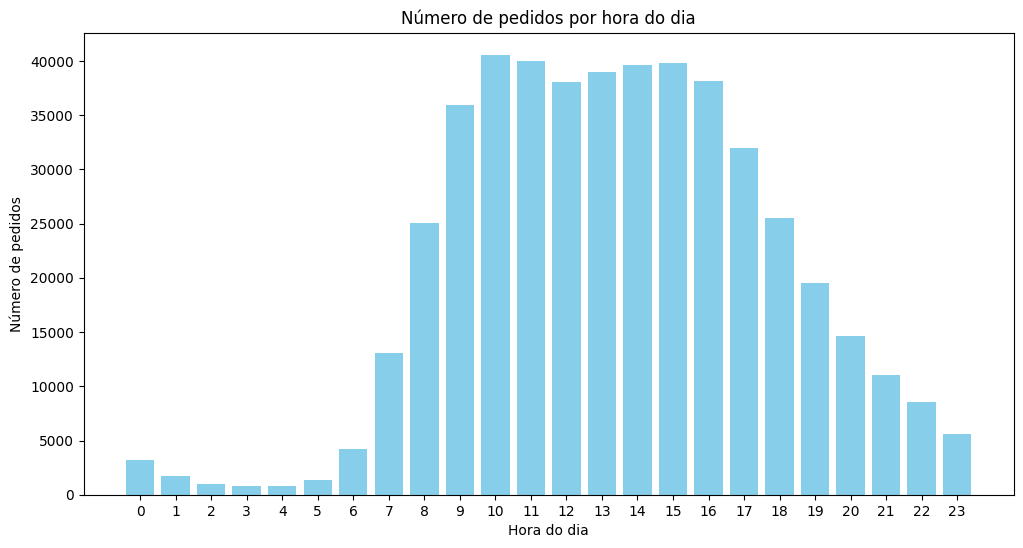

In [9]:
import matplotlib.pyplot as plt

# Contagem de pedidos por hora do dia
orders_per_hour = df_instacart_orders['order_hour_of_day'].value_counts().sort_index()
print(orders_per_hour)

# Criar o gráfico
plt.figure(figsize=(12,6))
plt.bar(orders_per_hour.index, orders_per_hour.values, color='skyblue')
plt.title("Número de pedidos por hora do dia")
plt.xlabel("Hora do dia")
plt.ylabel("Número de pedidos")
plt.xticks(range(0,24))  # garante que todas as horas apareçam no eixo x
plt.show()


Escreva suas conclusões aqui

Com base no gráfico de contagem de pedidos por hora:

Padrões de pico

A maioria dos pedidos ocorre durante o meio do dia (aproximadamente 10h às 15h) e no final da tarde (cerca de 18h), indicando horários de maior atividade dos clientes.

Menor movimento

As horas mais tranquilas são madrugada e início da manhã (0h às 5h), com número muito reduzido de pedidos.

Comportamento do usuário

O gráfico revela hábitos consistentes de compra: os clientes tendem a fazer pedidos antes ou depois do horário de almoço e à noite, possivelmente refletindo o consumo doméstico e a logística de entrega.


### [A3] Em que dia da semana as pessoas compram produtos alimentícios?

0    84090
1    82185
2    65833
3    60912
4    59810
5    63488
6    62649
Name: order_dow, dtype: int64


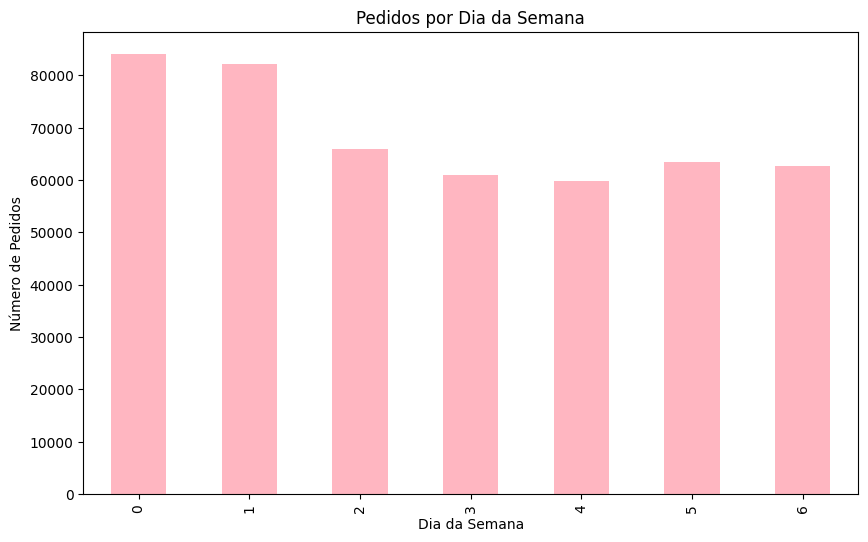

In [72]:

import matplotlib.pyplot as plt

orders_by_day = df_instacart_orders['order_dow'].value_counts().sort_index()
print(orders_by_day)

plt.figure(figsize=(10,6))
orders_by_day.plot(kind='bar', color='lightpink')
plt.title('Pedidos por Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Número de Pedidos')
plt.show()


Compras de produtos alimentícios por dia da semana:
Domingo    33378
Segunda    28708
Terça      21926
Quarta     20087
Quinta     19659
Sexta      20658
Sábado     24230
Name: order_dow, dtype: int64


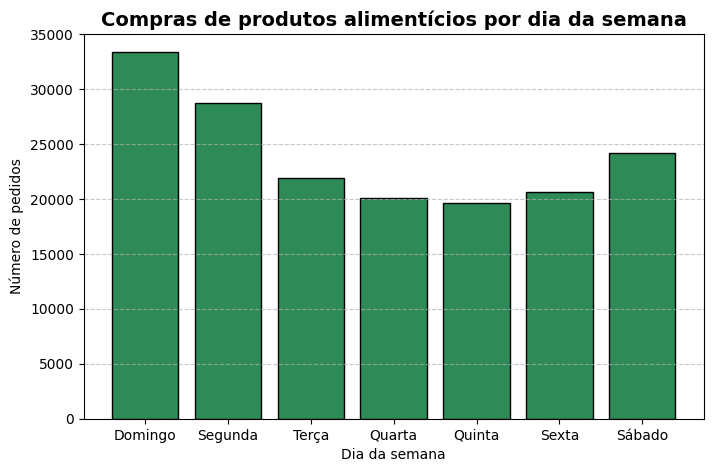

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("/datasets/instacart_orders.csv", sep=';')
order_products = pd.read_csv("/datasets/order_products.csv", sep=';')
products = pd.read_csv("/datasets/products.csv", sep=';')
aisles = pd.read_csv("/datasets/aisles.csv", sep=';')
departments = pd.read_csv("/datasets/departments.csv", sep=';')

dados = (
    order_products
    .merge(orders, on='order_id')
    .merge(products, on='product_id')
    .merge(aisles, on='aisle_id')
    .merge(departments, on='department_id')
)

produtos_alimenticios = dados[dados['aisle'].str.contains('food', case=False, na=False)]

compras_por_dia = produtos_alimenticios['order_dow'].value_counts().sort_index()

dias_semana = ['Domingo', 'Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado']
compras_por_dia.index = [dias_semana[i] for i in compras_por_dia.index]

print("Compras de produtos alimentícios por dia da semana:")
print(compras_por_dia)

plt.figure(figsize=(8,5))
plt.bar(compras_por_dia.index, compras_por_dia.values, color='seagreen', edgecolor='black')
plt.title("Compras de produtos alimentícios por dia da semana", fontsize=14, fontweight='bold')
plt.xlabel("Dia da semana")
plt.ylabel("Número de pedidos")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Escreva suas conclusões aqui

Com base no gráfico de pedidos por dia da semana:

Padrões de pico

A maior parte dos pedidos ocorre nos inicio da semana (geralmente domingo e segunda, 0-1), indicando dias de maior atividade dos clientes.

Menor movimento

Na quinta-feira (4) e, em alguns casos, na quarta-feira (3) apresentam o menor número de pedidos, refletindo menor atividade nesses dias.

Comportamento do usuário

Os clientes tendem a fazer pedidos de forma concentrada aos domingos, possivelmente relacionados a rotina de compras domésticas e planejamento semanal.



### [A4] Quanto tempo as pessoas esperam até fazer outro pedido?

Escreva suas conclusões aqui

Com base nos dados do número de dias desde o último pedido:

Picos de frequência

Observa-se que 7 dias (uma semana) e 30 dias (um mês) são os intervalos mais comuns entre pedidos, indicando que muitos clientes têm rotina semanal ou mensal de compras.

Outros intervalos

Intervalos de 1 a 6 dias também são frequentes, refletindo clientes que compram mais frequentemente, possivelmente para reposição rápida de produtos.

Há uma queda gradual em intervalos intermediários (8 a 29 dias), com pequenas exceções (como o pico em 14 dias), sugerindo padrões de compra menos frequentes para alguns usuários.

Valores atípicos

O valor 0 representa clientes que fizeram o primeiro pedido, já que não há pedido anterior.

Esse valor é menor que os picos semanais e mensais, confirmando que a maior parte dos pedidos vem de clientes recorrentes.


0.0      9589
1.0     20179
2.0     27141
3.0     30225
4.0     31007
5.0     30096
6.0     33931
7.0     44579
8.0     25361
9.0     16754
10.0    13310
11.0    11467
12.0    10658
13.0    11737
14.0    13992
15.0     9416
16.0     6588
17.0     5498
18.0     4972
19.0     4939
20.0     5302
21.0     6448
22.0     4514
23.0     3337
24.0     3015
25.0     2711
26.0     2640
27.0     2986
28.0     3745
29.0     2673
30.0    51338
Name: days_since_prior_order, dtype: int64


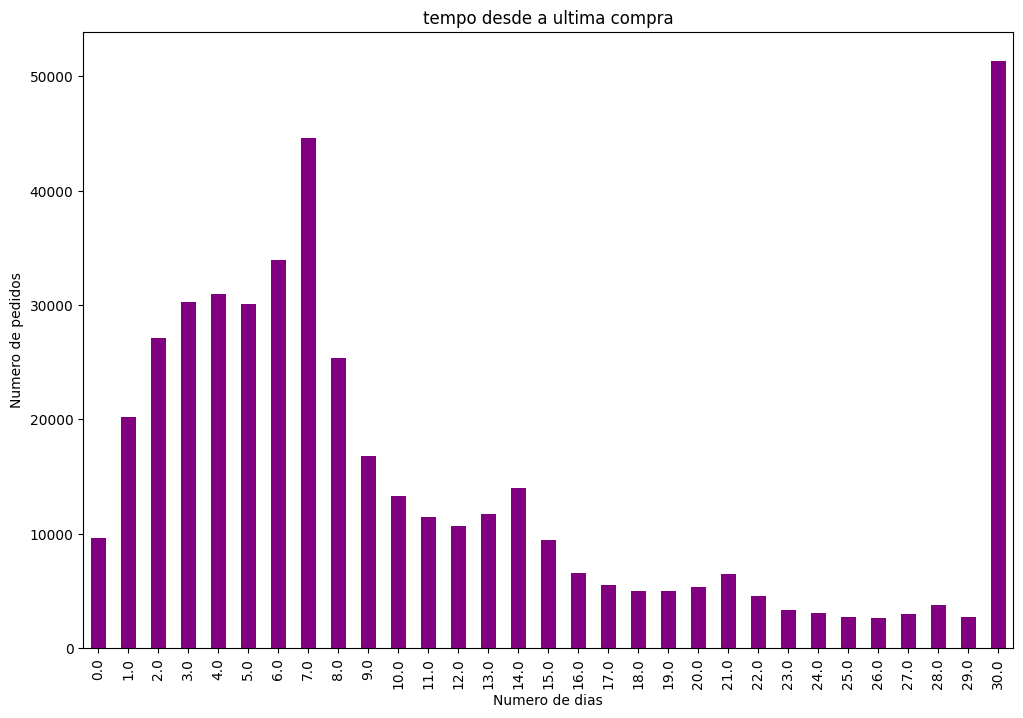

In [8]:


import matplotlib.pyplot as plt 

prior_order = df_instacart_orders['days_since_prior_order'].value_counts().sort_index()
print(prior_order)

plt.figure(figsize=(12,8))
prior_order.plot(kind='bar', color='purple')
plt.title('tempo desde a ultima compra')
plt.xlabel('Numero de dias')
plt.ylabel('Numero de pedidos')
plt.show()



# [B] Médio (é necessário concluir tudo para passar)

1.	Há alguma diferença nas distribuições de `'order_hour_of_day'` nas quartas e sábados? Construa gráficos de barras para ambos os dias no mesmo gráfico e descreva as diferenças que você notou.
2.	Construa um gráfico de distribuição para o número de pedidos que os clientes fazem (ou seja, quantos clientes fizeram apenas 1 pedido, quantos fizeram apenas 2, quantos apenas 3, etc.)
3.	Quais são os 20 produtos comprados com mais frequência? Exiba os IDs e nomes.


### [B1] Diferenças nas quartas e sábados em `'order_hour_of_day'`. Crie gráficos de barras para ambos os dias e descreva as diferenças.

In [20]:
# Filtrar pedidos por dia
wednesday_orders = df_instacart_orders[df_instacart_orders['order_dow'] == 3]
saturday_orders = df_instacart_orders[df_instacart_orders['order_dow'] == 6]

In [21]:
# Contar pedidos por hora
wed_hourly = wednesday_orders['order_hour_of_day'].value_counts().sort_index()
sat_hourly = saturday_orders['order_hour_of_day'].value_counts().sort_index()

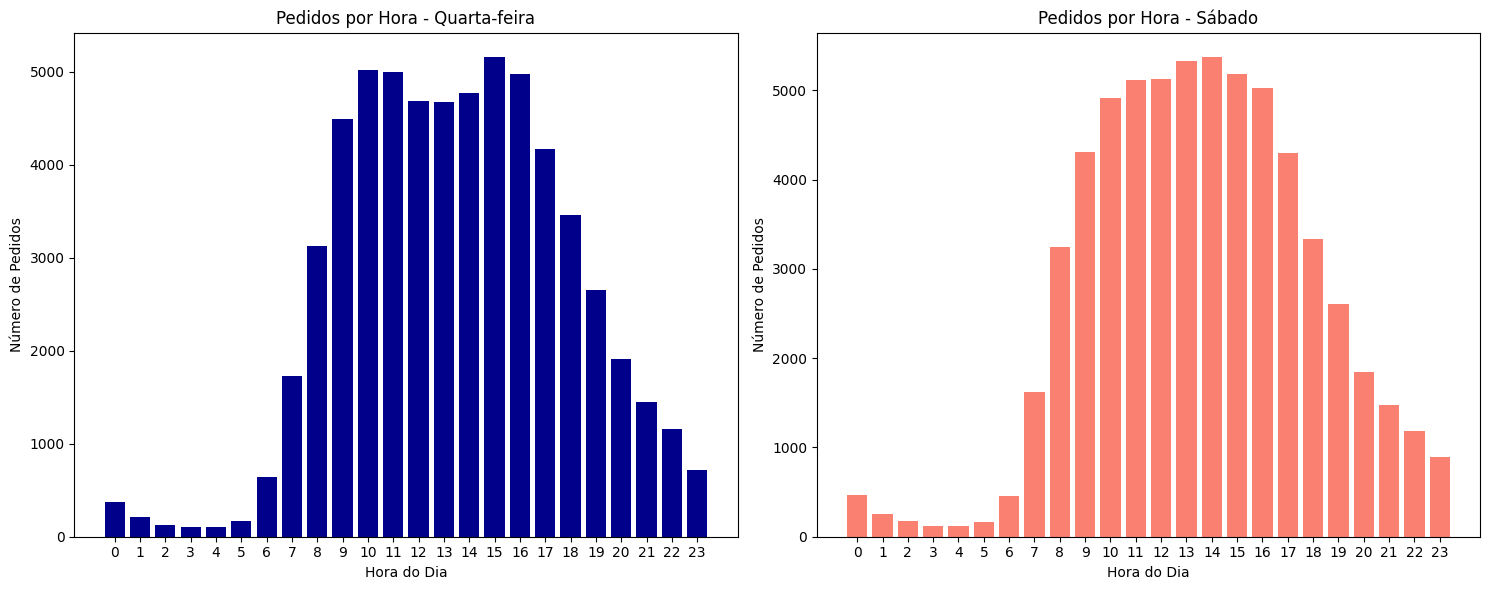

In [24]:

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

# Gráfico para quarta-feira
plt.subplot(1, 2, 1)
plt.bar(wed_hourly.index, wed_hourly.values, color='darkblue')
plt.title('Pedidos por Hora - Quarta-feira')
plt.xlabel('Hora do Dia')
plt.ylabel('Número de Pedidos')
plt.xticks(range(0, 24))

# Gráfico para sábado
plt.subplot(1, 2, 2)
plt.bar(sat_hourly.index, sat_hourly.values, color='salmon')
plt.title('Pedidos por Hora - Sábado')
plt.xlabel('Hora do Dia')
plt.ylabel('Número de Pedidos')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()



<Figure size 640x480 with 0 Axes>

Escreva suas conclusões aqui


Observações sobre os gráficos

Quarta-feira (wed_hourly)

Os pedidos se concentram principalmente pela manhã e a tarde (cerca de 10h–16h) com pico maior as 15h

Isso indica o padrão de compra de clientes durante dias úteis, possivelmente compras menores e frequentes.

Sábado (sat_hourly)

Os pedidos tendem a se concentrar entre 9h e 17h com o pico de pedidos as 14h

Reflete o comportamento de compras de fim de semana, geralmente para reposição semanal ou compras maiores.

Resumo da comparação:

Quartas e Sábado: o pico de pedidos são praticamente semelhantes, indicando que os clientes costumam fazer mais pedidos entre esses horários do dia independentemente do dia da semana.


### [B2] Qual é a distribuição do número de pedidos por cliente?

1     55357
2     36508
3     21547
4     13498
5      8777
6      6012
7      4240
8      3019
9      2152
10     1645
11     1308
12      947
13      703
14      512
15      437
16      263
17      184
18      121
19       85
20       52
21       22
22       23
23       19
24        3
25        1
26        1
28        1
Name: order_id, dtype: int64


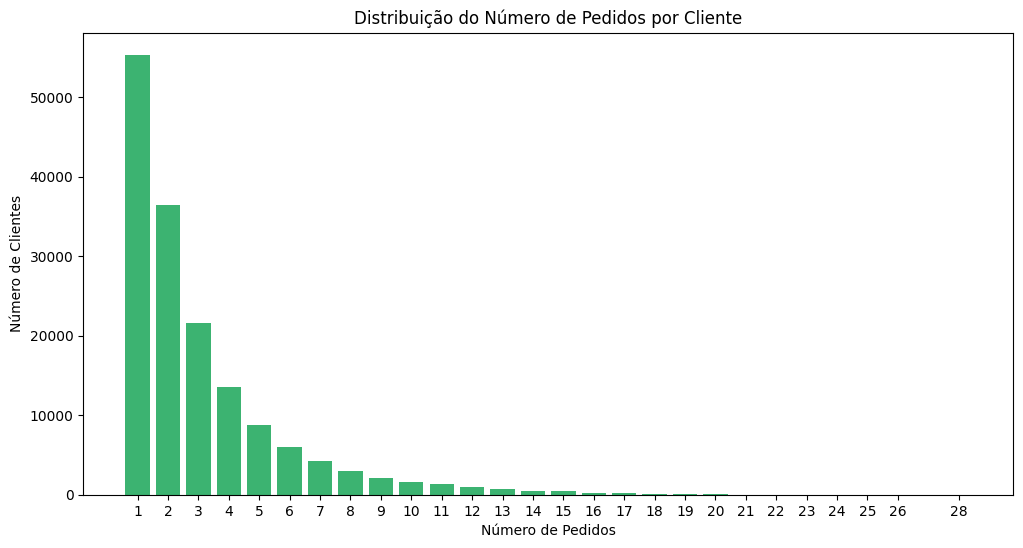

In [28]:

import matplotlib.pyplot as plt

# Contar quantos pedidos cada cliente fez
orders_per_user = df_instacart_orders.groupby('user_id')['order_id'].nunique()

# Contar quantos clientes fizeram 1 pedido, 2 pedidos, 3 pedidos, etc.
distribution = orders_per_user.value_counts().sort_index()
print(distribution)

# Gráfico de distribuição
plt.figure(figsize=(12,6))
plt.bar(distribution.index, distribution.values, color='mediumseagreen')
plt.title('Distribuição do Número de Pedidos por Cliente')
plt.xlabel('Número de Pedidos')
plt.ylabel('Número de Clientes')
plt.xticks(distribution.index)
plt.show()


Escreva suas conclusões aqui

Conclusão da Distribuição de Pedidos por Cliente

Maioria dos clientes faz poucos pedidos

- 55.357 clientes fizeram apenas 1 pedido.

- 36.508 clientes fizeram 2 pedidos.

Isso indica que grande parte da base é composta por clientes ocasionais.

Clientes recorrentes

Um número menor de clientes fez muitos pedidos:

- 4 pedidos: 13.498 clientes

- 10 pedidos: 1.645 clientes

- 20+ pedidos: poucos clientes (menos de 50)

Esses representam a base de clientes fiéis que compram com frequência.

Padrão geral

A distribuição é fortemente assimétrica/direita, típica de comportamento de e-commerce: poucos clientes compram muito, enquanto a maioria compra pouco.


### [B3] Quais são os 20 produtos mais populares? Exiba os IDs e nomes.

In [29]:
# Contar frequência de cada produto
product_counts = df_order_products['product_id'].value_counts()
print('Top 5 produtos mais comprados:')
print(product_counts.head())

Top 5 produtos mais comprados:
24852    66050
13176    53297
21137    37039
21903    33971
47209    29773
Name: product_id, dtype: int64


In [31]:
# Selecionar os 20 primeiros
top_20_products = product_counts.head(20)

In [32]:

# Converter para DataFrame para facilitar o merge
top_20_df = top_20_products.reset_index()
top_20_df.columns = ['product_id', 'purchase_count']
# Fazer merge com a tabela de produtos para obter os nomes
top_20_with_names = top_20_df.merge(df_products[['product_id', 'product_name']],
                                   on='product_id',
                                   how='left')
print(top_20_with_names)


    product_id  purchase_count              product_name
0        24852           66050                    Banana
1        13176           53297    Bag of Organic Bananas
2        21137           37039      Organic Strawberries
3        21903           33971      Organic Baby Spinach
4        47209           29773      Organic Hass Avocado
5        47766           24689           Organic Avocado
6        47626           21495               Large Lemon
7        16797           20018              Strawberries
8        26209           19690                     Limes
9        27845           19600        Organic Whole Milk
10       27966           19197       Organic Raspberries
11       22935           15898      Organic Yellow Onion
12       24964           15292            Organic Garlic
13       45007           14584          Organic Zucchini
14       39275           13879       Organic Blueberries
15       49683           13675            Cucumber Kirby
16       28204           12544 

Escreva suas conclusões aqui

Produtos predominantes

- A lista é dominada por frutas e vegetais, principalmente orgânicos: banana, morango, abacate, limão, etc.

- O produto mais comprado é a Banana, com 66.050 unidades, seguido por Bag of Organic Bananas.

Preferência por produtos orgânicos

- A maioria dos itens possui a palavra "Organic" no nome, indicando alta preferência por produtos orgânicos na base analisada.

Categorias dominantes

- Frutas, vegetais e alguns laticínios aparecem com frequência, refletindo hábitos de compra de alimentos frescos e saudáveis.

Informação útil para marketing e estoque

# [C] Difícil (é necessário concluir pelo menos duas perguntas para passar)

1.	Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?
2.	Quais são os 20 principais itens incluídos mais frequentemente em pedidos repetidos? Exiba os IDs e nomes.
3.	Para cada produto, qual parcela de seus pedidos são repetidos? Crie uma tabela com colunas de ID e nome do produto e a proporção de pedidos repetidos.
4.	Para cada cliente, qual proporção de todos os seus pedidos são repetidos?
5.	Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros? Exiba o ID do produto, nome e o número de vezes que ele foi o primeiro a ser adicionado a um carrinho.


### [C1] Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?

In [52]:
# Calcular quantos itens cada pedido tem
itens_por_pedido = df_order_products.groupby('order_id')['product_id'].count()

In [54]:
# Estatísticas básicas
print("Estatísticas sobre quantidade de itens por pedido:")
print(itens_por_pedido.describe())

Estatísticas sobre quantidade de itens por pedido:
count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
Name: product_id, dtype: float64


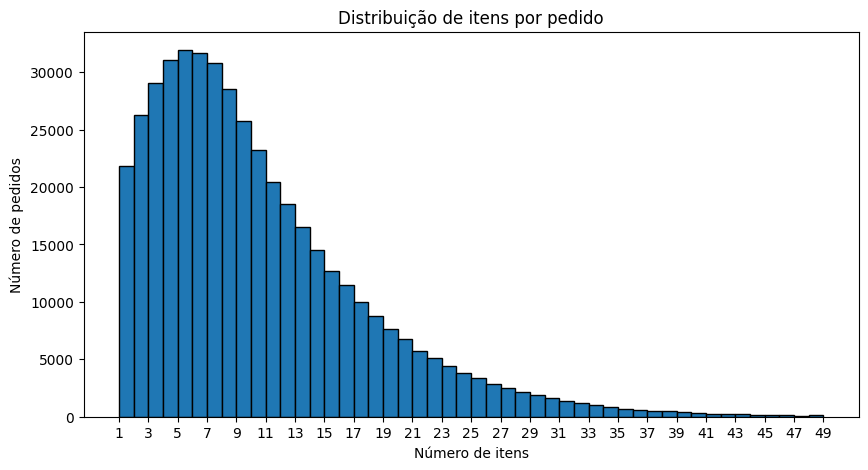

In [55]:
# Exibir distribuição (histograma)
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.hist(itens_por_pedido, bins=range(1, 50), edgecolor='black')  
plt.title('Distribuição de itens por pedido')
plt.xlabel('Número de itens')
plt.ylabel('Número de pedidos')
plt.xticks(range(1, 50, 2))
plt.show()

Escreva suas conclusões aqui

Os clientes compram em média cerca de 10 itens por pedido, mas a mediana é 8 itens, mostrando que a maioria dos pedidos é relativamente pequena.

Há uma cauda longa à direita, ou seja, existem poucos pedidos muito grandes (até 127 itens), que elevam a média, mas são exceções.

A maior parte dos pedidos concentra-se entre 2 e 10 itens.

Comportamento do cliente:

Clientes tendem a fazer compras moderadas, consistentes com consumo doméstico diário ou semanal.

Compras muito grandes são raras e provavelmente representam compras de empresas ou estoques especiais.


### [C2] Quais são os 20 principais itens incluídos com mais frequência em pedidos repetidos? Exiba os IDs e nomes.

In [48]:
# Filtrar produtos que foram repetidos
itens_reordered = df_order_products[df_order_products['reordered'] == 1]
print(f"Total de itens repetidos: {len(itens_reordered)}")


Total de itens repetidos: 2683838


In [49]:
# Contar quantas vezes cada produto foi repetido
itens_counts = itens_reordered['product_id'].value_counts()
print("Top 5 primeiros itens:")
print(itens_counts.head())


Top 5 primeiros itens:
24852    55763
13176    44450
21137    28639
21903    26233
47209    23629
Name: product_id, dtype: int64


In [50]:
# Selecionar os 20 primeiros
top_20 = itens_counts.head(20)

In [47]:
# Selecionar os 20 primeiros
top_20 = itens_counts.head(20)

# Converter para DataFrame e ajustar nomes das colunas
top_20_df = top_20.reset_index()
top_20_df.columns = ['product_id', 'itens_counts']

# Merge com nomes dos produtos
result = top_20_df.merge(df_products[['product_id', 'product_name']], 
                          on='product_id', 
                          how='left')

print(result)

    product_id  itens_counts              product_name
0        24852         55763                    Banana
1        13176         44450    Bag of Organic Bananas
2        21137         28639      Organic Strawberries
3        21903         26233      Organic Baby Spinach
4        47209         23629      Organic Hass Avocado
5        47766         18743           Organic Avocado
6        27845         16251        Organic Whole Milk
7        47626         15044               Large Lemon
8        27966         14748       Organic Raspberries
9        16797         13945              Strawberries
10       26209         13327                     Limes
11       22935         11145      Organic Yellow Onion
12       24964         10411            Organic Garlic
13       45007         10076          Organic Zucchini
14       49683          9538            Cucumber Kirby
15       28204          8989        Organic Fuji Apple
16        8277          8836  Apple Honeycrisp Organic
17       3

Escreva suas conclusões aqui

A lista é dominada por frutas e vegetais orgânicos, como Banana, Bag of Organic Bananas, Organic Strawberries, Organic Hass Avocado.

Isso indica que os clientes tendem a recomprar itens frescos regularmente, especialmente frutas e vegetais orgânicos, possivelmente devido ao consumo diário e à preferência por produtos saudáveis.

Itens com alta contagem absoluta de repetições:

O produto mais repetido, Banana, foi comprado novamente 55.763 vezes, seguido por Bag of Organic Bananas (44.450).

Essa diferença sugere que produtos básicos ou populares têm maior recorrência absoluta.

Além de frutas, há vegetais (como Organic Baby Spinach, Organic Zucchini) e laticínios (como Organic Half & Half), mostrando que a repetição de pedidos não se restringe a um tipo específico de produto, mas segue padrões de consumo diário.

os produtos mais repetidos refletem preferências de consumo saudável e itens essenciais para o dia a dia, com frutas e vegetais orgânicos liderando a lista, o que pode orientar decisões de marketing e estoque.

### [C3] Para cada produto, qual parcela de todos os pedidos dele são repetidos?

In [56]:
# Contar total de pedidos para cada produto
total_pedidos = df_order_products.groupby('product_id')['order_id'].count()

# Contar quantos pedidos de cada produto foram repetidos (reordered == 1)
pedidos_repetidos = df_order_products[df_order_products['reordered'] == 1] \
                    .groupby('product_id')['order_id'].count()

# Calcular a parcela de pedidos repetidos
parcela_repetidos = (pedidos_repetidos / total_pedidos).fillna(0)  # produtos sem repetição recebem 0


In [57]:
# Converter para DataFrame e juntar com nomes dos produtos
df_parcela = parcela_repetidos.reset_index()
df_parcela.columns = ['product_id', 'parcela_repetidos']

df_parcela = df_parcela.merge(df_products[['product_id', 'product_name']], 
                              on='product_id', how='left')

In [58]:
# Ordenar do mais repetido para o menos repetido
df_parcela = df_parcela.sort_values(by='parcela_repetidos', ascending=False)

# Mostrar os top 20 produtos com maior parcela de repetição
print(df_parcela.head(20))

       product_id  parcela_repetidos  \
13453       14721                1.0   
19195       20949                1.0   
6136         6723                1.0   
6144         6732                1.0   
41319       45088                1.0   
41310       45078                1.0   
19258       21016                1.0   
19248       21005                1.0   
32273       35192                1.0   
32277       35197                1.0   
6211         6810                1.0   
41274       45040                1.0   
41269       45035                1.0   
25120       27373                1.0   
28203       30748                1.0   
41265       45031                1.0   
32224       35137                1.0   
28202       30747                1.0   
32304       35228                1.0   
32305       35229                1.0   

                                            product_name  
13453                            Bone Strength Take Care  
19195                           Vanilla S

Escreva suas conclusões aqui

Todos os pedidos desses produtos foram recomprados pelos clientes.

Isso indica uma alta dependência ou preferência do cliente por esses itens, possivelmente porque são consumíveis frequentes, suplementos, snacks ou itens específicos de marca.


### [C4] Para cada cliente, qual proporção de todos os seus pedidos são repetidos?

In [71]:
# Primeiro, fazer merge para conectar user_id com os produtos
df_merged = df_order_products.merge(
    df_instacart_orders[['order_id', 'user_id']], 
    on='order_id', 
    how='left'
)
# Contar total de pedidos por usuário
Total_user_order = df_merged.groupby('user_id')['order_id'].count()

# Contar quantos pedidos de cada usuário foram repetidos
orders_reordered = df_merged[df_merged['reordered'] == 1].groupby('user_id')['order_id'].count()

# Calcular proporção de pedidos repetidos
repeated_by_user= (orders_reordered / Total_user_order).fillna(0)

# Converter para DataFrame
df_repeated_by_user = repeated_by_user.reset_index()
df_repeated_by_user.columns = ['user_id', 'proporcao_repetidos']

# Estatísticas gerais
print(df_repeated_by_user.describe())

# Exibir os top 10 usuários com maior proporção de pedidos repetidos
print(df_repeated_by_user.sort_values(by='proporcao_repetidos', ascending=False).head(10))


             user_id  proporcao_repetidos
count  149626.000000        149626.000000
mean   103205.167778             0.494853
std     59560.993992             0.292685
min         2.000000             0.000000
25%     51650.250000             0.272727
50%    103177.000000             0.500000
75%    154837.750000             0.724138
max    206209.000000             1.000000
        user_id  proporcao_repetidos
69912     96430                  1.0
49962     69003                  1.0
145051   199910                  1.0
147525   203290                  1.0
101447   140076                  1.0
63567     87731                  1.0
49967     69010                  1.0
130094   179451                  1.0
143217   197349                  1.0
124825   172208                  1.0


Escreva suas conclusões aqui

Número total de clientes analisados: 149.626

Média de pedidos repetidos: ~0,495 → em média, 49,5% dos pedidos de um cliente são recompras.

Mediana: 0,5 → metade dos clientes tem pelo menos 50% de seus pedidos como repetidos.

Quartis:

25% dos clientes têm ≤ 27% de pedidos repetidos

75% dos clientes têm ≤ 72% de pedidos repetidos

Extremos:

Mínimo: 0 → clientes que nunca repetiram pedidos

Máximo: 1 → clientes que sempre repetem todos os pedidos

Alguns clientes nunca repetem pedidos, enquanto outros têm 100% de recompra, indicando forte fidelidade.

A média e a mediana próximas de 0,5 indicam que a base é bem equilibrada entre clientes fiéis e clientes ocasionais.

### [C5] Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros?

In [33]:
# Filtrar produtos que foram adicionados primeiro ao carrinho
first_items = df_order_products[df_order_products['add_to_cart_order'] == 1]
print(f"Total de primeiros itens: {len(first_items)}")

Total de primeiros itens: 450046


In [35]:
# Contar quantas vezes cada produto foi o primeiro item
first_item_counts = first_items['product_id'].value_counts()
print("Top 5 primeiros itens:")
print(first_item_counts.head())
# Selecionar os 20 primeiros
top_20_first = first_item_counts.head(20)

Top 5 primeiros itens:
24852    15562
13176    11026
27845     4363
21137     3946
47209     3390
Name: product_id, dtype: int64


In [36]:

# Converter para DataFrame e fazer merge
top_20_first_df = top_20_first.reset_index()
top_20_first_df.columns = ['product_id', 'first_item_count']

# Merge com nomes dos produtos
result = top_20_first_df.merge(df_products[['product_id', 'product_name']], 
                               on='product_id', 
                               how='left')
print(result)


    product_id  first_item_count                 product_name
0        24852             15562                       Banana
1        13176             11026       Bag of Organic Bananas
2        27845              4363           Organic Whole Milk
3        21137              3946         Organic Strawberries
4        47209              3390         Organic Hass Avocado
5        21903              3336         Organic Baby Spinach
6        47766              3044              Organic Avocado
7        19660              2336                 Spring Water
8        16797              2308                 Strawberries
9        27966              2024          Organic Raspberries
10       44632              1914   Sparkling Water Grapefruit
11       49235              1797          Organic Half & Half
12       47626              1737                  Large Lemon
13         196              1733                         Soda
14       38689              1397     Organic Reduced Fat Milk
15      

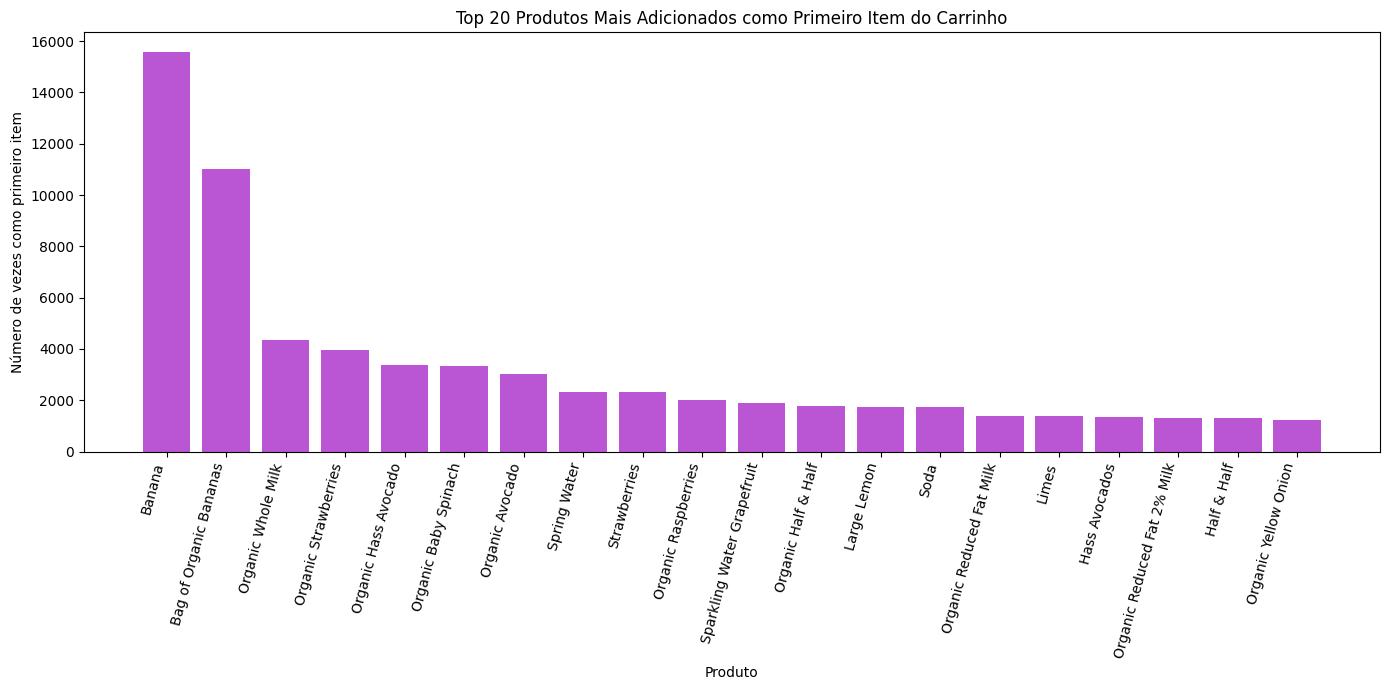

In [38]:
import matplotlib.pyplot as plt

# Ordenar os produtos pelo número de vezes que foram adicionados primeiro
top_first_products = result.sort_values('first_item_count', ascending=False)

plt.figure(figsize=(14,7))
plt.bar(top_first_products['product_name'], top_first_products['first_item_count'], color='mediumorchid')
plt.title('Top 20 Produtos Mais Adicionados como Primeiro Item do Carrinho')
plt.xlabel('Produto')
plt.ylabel('Número de vezes como primeiro item')
plt.xticks(rotation=75, ha='right')  # deixa os nomes legíveis
plt.tight_layout()
plt.show()

Escreva suas conclusões aqui

Os produtos dominantes como primeiro item são frutas, especialmente Bananas e Bag of Organic Bananas, lideram a lista, indicando que clientes frequentemente começam suas compras por itens frescos.

Preferência por produtos orgânicos e saudáveis

Muitos produtos são orgânicos (ex: Organic Whole Milk, Organic Strawberries, Organic Avocado), mostrando tendência de escolha consciente e saudável ao iniciar o carrinho.

Outros produtos frequentes

Alguns itens não orgânicos ou bebidas (ex: Spring Water, Soda, Sparkling Water Grapefruit) também aparecem entre os primeiros, sugerindo que hidratantes ou básicos também são prioridade de compra.



# Conclusão geral do projeto:

O projeto permitiu entender profundamente o comportamento dos clientes Instacart, identificando padrões de frequência, horários e dias de pedidos, bem como os produtos mais populares e recorrência de compras.
A análise dos dados da Instacart revelou que a maior parte dos clientes realiza poucos pedidos, enquanto uma minoria é recorrente. Os pedidos apresentam picos no meio do dia e dias úteis, com hábitos semanais e mensais claros. Os produtos mais comprados são frutas, vegetais e orgânicos, mostrando preferência por alimentos frescos e saudáveis.
O projeto evidenciou tambem que o comportamento de recompra está fortemente ligado a produtos essenciais e saudáveis, enquanto a fidelidade dos clientes varia consideravelmente, permitindo estratégias segmentadas de marketing e gestão de estoque. Produtos e clientes com alta repetição oferecem oportunidades de negócio previsíveis e de maior valor, enquanto aqueles com baixa repetição indicam espaço para crescimento e engajamento.